# DATA SCIENCE INTERN @OASIS INFOBYTE

## AUTHOR : SHREENIDHI MEDAR

# Task 2 : Unemployment Analysis with Python

## 1. Import Libraries

In [1]:
# Core libraries for data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Notebook settings

In [2]:
import warnings
warnings.filterwarnings('ignore')

# Clean chart style and default chart size
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14

# Show charts inside the notebook
%matplotlib inline

## 2. Load the Dataset

In [3]:
# Libraries for finding the file on disk
import os
import glob

# ---- Choose the data file ----
# Leave as None to auto-detect, or force a file: DATA_FILE = 'your_file.csv'
DATA_FILE = None

CANDIDATES = [
    'Unemployment in India.csv',
    'Unemployment_Rate_upto_11_2020.csv',
    'Unemployment_in_India.csv',
]

if DATA_FILE is None:
    found = [f for f in CANDIDATES if os.path.exists(f)]
    if not found:
        # fall back to any CSV with "unemploy" in its name
        found = sorted(f for f in glob.glob('*.csv') if 'unemploy' in f.lower())
    if not found:
        raise FileNotFoundError(
            "Dataset not found. Download 'Unemployment in India' from Kaggle and place the "
            "CSV in the same folder as this notebook (or set DATA_FILE above)."
        )
    DATA_FILE = found[0]

print('Loading file:', DATA_FILE)
raw = pd.read_csv(DATA_FILE)
print('Raw shape  :', raw.shape)
raw.head()

Loading file: Unemployment in India.csv
Raw shape  : (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 3. Data Inspection and Cleaning

In [4]:
# Shape and column names (note: the raw Kaggle file has stray spaces in some column names)
print('Shape (rows, columns):', raw.shape)
print('\nColumn names:')
print(list(raw.columns))
raw.head()

Shape (rows, columns): (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [5]:
# Data types and non-null counts
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [6]:
# Null value check and duplicate check
print('Missing values per column:')
print(raw.isnull().sum())
print('\nTotal missing values:', int(raw.isnull().sum().sum()))
print('Duplicate rows      :', int(raw.duplicated().sum()))

Missing values per column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Total missing values: 196
Duplicate rows      : 27


### 3.1 Settings used in the analysis

In [7]:
# India's nationwide COVID-19 lockdown began on 25 March 2020.
# This date marks the charts and splits the data into pre- and post-COVID periods.
LOCKDOWN_DATE = pd.Timestamp('2020-03-25')

# The three numeric measures used throughout the analysis
METRICS = ['Unemployment_Rate', 'Employed', 'LPR']

### 3.2 Clean the column names

In [8]:
df = raw.copy()

# 1) Tidy column names: strip stray spaces, then use short readable names
df.columns = df.columns.str.strip()
df = df.rename(columns={
    'Region': 'State',                                        # states / union territories
    'Region.1': 'Zone',                                       # North / South / East / West / Northeast
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',                         # headcount of employed people
    'Estimated Labour Participation Rate (%)': 'LPR',
})

required = ['State', 'Date', 'Unemployment_Rate', 'Employed', 'LPR']
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise KeyError(f'Expected columns not found: {missing_cols}. Columns present: {list(df.columns)}')

### 3.3 Remove null values and duplicates

In [9]:
# 2) Remove rows with nulls in key columns, and duplicates
rows_before = len(df)
df = df.dropna(subset=required).drop_duplicates()
print(f'Rows removed (nulls / duplicates): {rows_before - len(df)}')

Rows removed (nulls / duplicates): 28


### 3.4 Remove stray spaces from text values

In [10]:
# 3) Strip stray whitespace from text values (the Kaggle file has values like " 31-05-2019")
for col in df.columns:
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].apply(lambda v: v.strip() if isinstance(v, str) else v)

### 3.5 Type conversion (Date to datetime, metrics to numbers)

In [11]:
# 4) Type conversion: Date -> datetime (day-month-year format), metrics -> numeric
parsed = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce')
if parsed.isnull().mean() > 0.5:                              # fall back if the format differs
    parsed = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
df['Date'] = parsed
for col in METRICS:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop anything that failed conversion
bad_rows = df[['Date'] + METRICS].isnull().any(axis=1).sum()
df = df.dropna(subset=['Date'] + METRICS)
print(f'Rows dropped after type conversion: {bad_rows}')

Rows dropped after type conversion: 0


### 3.6 Sort and add time features, then check the cleaned data

In [12]:
# 5) Sort and add helpful time features
df = df.sort_values(['State', 'Date']).reset_index(drop=True)
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%b')

print('\nCleaned shape:', df.shape)
print('\nData types after conversion:')
print(df.dtypes)
print(f"\nDate range : {df['Date'].min():%d %b %Y}  to  {df['Date'].max():%d %b %Y}")
print('States     :', df['State'].nunique())
print('Months     :', df['Date'].nunique())
df.head()


Cleaned shape: (740, 10)

Data types after conversion:
State                        object
Date                 datetime64[ns]
Frequency                    object
Unemployment_Rate           float64
Employed                    float64
LPR                         float64
Area                         object
Year                          int64
Month                         int64
Month_Name                   object
dtype: object

Date range : 31 May 2019  to  30 Jun 2020
States     : 28
Months     : 14


,State,Date,Frequency,Unemployment_Rate,Employed,LPR,Area,Year,Month,Month_Name
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019,5,May
1,Andhra Pradesh,2019-05-31,Monthly,6.09,4788661.0,37.45,Urban,2019,5,May
2,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,2019,6,Jun
3,Andhra Pradesh,2019-06-30,Monthly,3.80,4824630.0,36.76,Urban,2019,6,Jun
4,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,2019,7,Jul


In [13]:
# Descriptive statistics for the numeric columns
df[METRICS].describe().round(2)

,Unemployment_Rate,Employed,LPR
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.50
max,76.74,45777509.00,72.57


**What the three measures mean**
- **Unemployment_Rate**: % of the labour force that is without work and looking for work.
- **LPR** (Labour Participation Rate): % of the working-age population that is working or looking for work.
- **Employed**: estimated *number* of employed people. This is a **headcount, not a rate**. The dataset has no employment *rate* column, so `Employed` is used as the employment measure in the correlation analysis (Section 7).

## 4. EDA: Region-wise Averages and Month-wise Trends

### 4.1 State-wise (region-wise) averages

In [14]:
# Library for showing tables nicely in Jupyter
from IPython.display import display

# Average of each metric per state, sorted by unemployment rate (highest first)
state_avg = (
    df.groupby('State')[METRICS]
      .mean()
      .round(2)
      .sort_values('Unemployment_Rate', ascending=False)
)
display(state_avg)

# Quick auto-generated takeaway (computed from the data)
print(f"\nHighest average unemployment: {state_avg.index[0]} ({state_avg['Unemployment_Rate'].iloc[0]:.1f}%)")
print(f"Lowest  average unemployment: {state_avg.index[-1]} ({state_avg['Unemployment_Rate'].iloc[-1]:.1f}%)")
print(f"Average across all states    : {state_avg['Unemployment_Rate'].mean():.1f}%")

,Unemployment_Rate,Employed,LPR
State,,,
Tripura,28.35,717002.64,61.82
Haryana,26.28,3557072.46,42.74
Jharkhand,20.58,4469240.43,41.67
Bihar,18.92,12366189.14,38.15
Himachal Pradesh,18.54,1059823.71,44.22
Delhi,16.50,2627512.86,38.93
Jammu & Kashmir,16.19,1799931.67,41.03
Chandigarh,15.99,316831.25,39.34
Rajasthan,14.06,10041064.75,39.97



Highest average unemployment: Tripura (28.4%)
Lowest  average unemployment: Meghalaya (4.8%)
Average across all states    : 11.8%


### 4.2 Zone-wise averages

,Unemployment_Rate,Employed,LPR
Area,,,
Urban,13.17,4388625.58,40.90
Rural,10.32,10192852.57,44.46


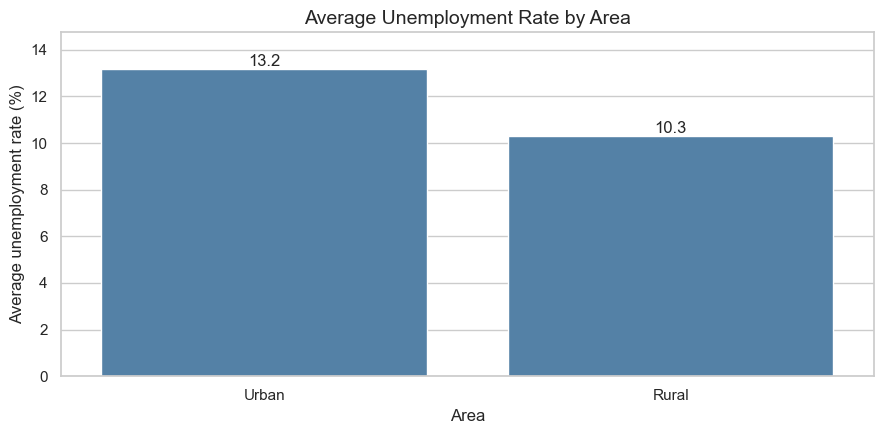

In [15]:
if 'Zone' in df.columns:
    group_col = 'Zone'
elif 'Area' in df.columns:
    group_col = 'Area'
else:
    group_col = None

if group_col:
    group_avg = (
        df.groupby(group_col)[METRICS].mean().round(2)
          .sort_values('Unemployment_Rate', ascending=False)
    )
    display(group_avg)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.barplot(x=group_avg.index, y=group_avg['Unemployment_Rate'], color='steelblue', ax=ax)
    ax.bar_label(ax.containers[0], fmt='%.1f')
    ax.margins(y=0.12)                                          # headroom so labels are not clipped
    ax.set_title(f'Average Unemployment Rate by {group_col}')
    ax.set_xlabel(group_col)
    ax.set_ylabel('Average unemployment rate (%)')
    plt.tight_layout()
    plt.show()
else:
    print('No Zone / Area column in this file, skipping this section.')

### 4.3 Month-wise trend (chronological)

,Unemployment_Rate,Employed,LPR,MoM_Change
Date,,,,
May 2019,8.87,7410148.44,43.90,NaN
Jun 2019,9.30,7358641.57,43.75,0.43
Jul 2019,9.03,7404425.31,43.71,-0.27
Aug 2019,9.64,7539815.19,43.65,0.61
Sep 2019,9.05,7739463.96,44.30,-0.59
Oct 2019,9.90,7298382.40,44.00,0.85
Nov 2019,9.87,7273660.64,44.11,-0.03
Dec 2019,9.50,7377387.83,43.67,-0.37
Jan 2020,9.95,7677344.42,44.05,0.45


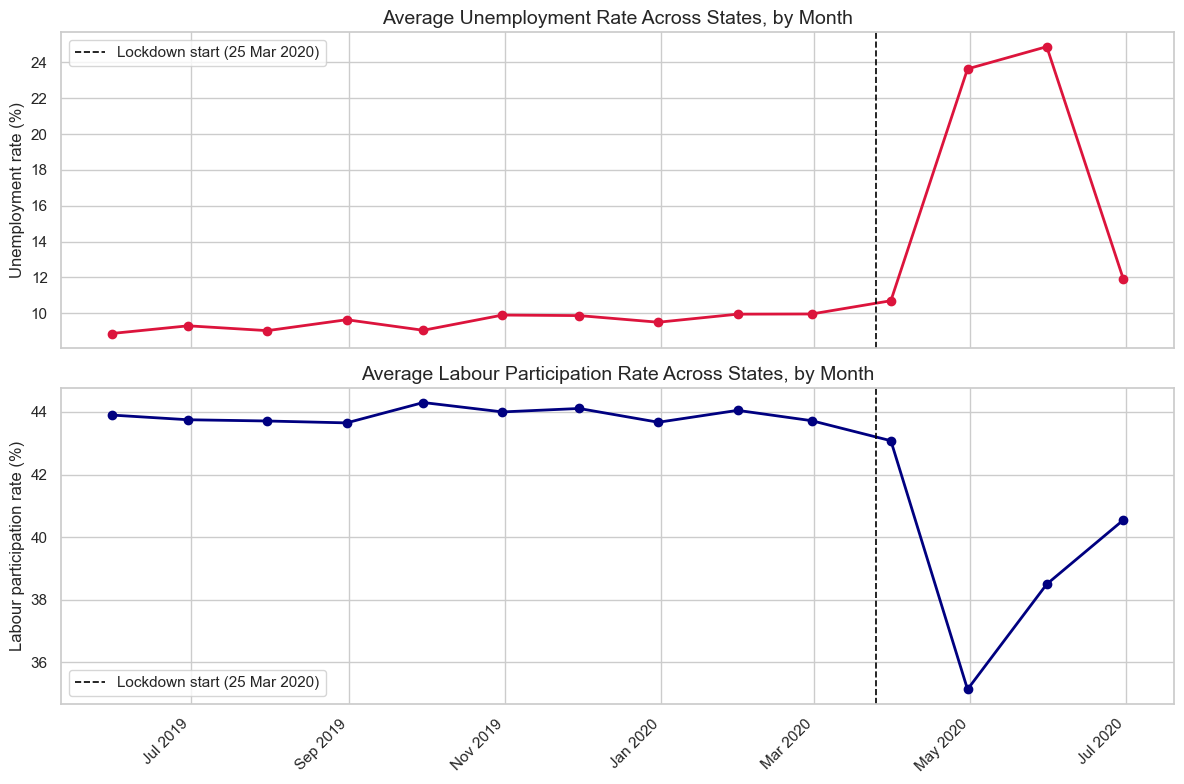

Peak average unemployment: 24.9% in May 2020


In [16]:
# Library for formatting dates on the chart axis
import matplotlib.dates as mdates

# Average across states for each month
monthly = df.groupby('Date')[METRICS].mean().round(2)
monthly['MoM_Change'] = monthly['Unemployment_Rate'].diff().round(2)     # month-on-month change

monthly_display = monthly.copy()
monthly_display.index = monthly_display.index.strftime('%b %Y')
display(monthly_display)

# Two stacked charts: unemployment rate (top) and labour participation rate (bottom)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(monthly.index, monthly['Unemployment_Rate'], marker='o', lw=2, color='crimson')
axes[0].set_ylabel('Unemployment rate (%)')
axes[0].set_title('Average Unemployment Rate Across States, by Month')

axes[1].plot(monthly.index, monthly['LPR'], marker='o', lw=2, color='navy')
axes[1].set_ylabel('Labour participation rate (%)')
axes[1].set_title('Average Labour Participation Rate Across States, by Month')

for ax, legend_pos in zip(axes, ['upper left', 'lower left']):   # keep legends off the lines
    ax.axvline(LOCKDOWN_DATE, color='black', ls='--', lw=1.2, label='Lockdown start (25 Mar 2020)')
    ax.legend(loc=legend_pos)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.show()

peak_month = monthly['Unemployment_Rate'].idxmax()
print(f"Peak average unemployment: {monthly['Unemployment_Rate'].max():.1f}% in {peak_month:%b %Y}")

## 5. Time-Series: Unemployment Over Time for Major States

States plotted: ['Delhi', 'Maharashtra', 'Tamil Nadu', 'Karnataka', 'Bihar']


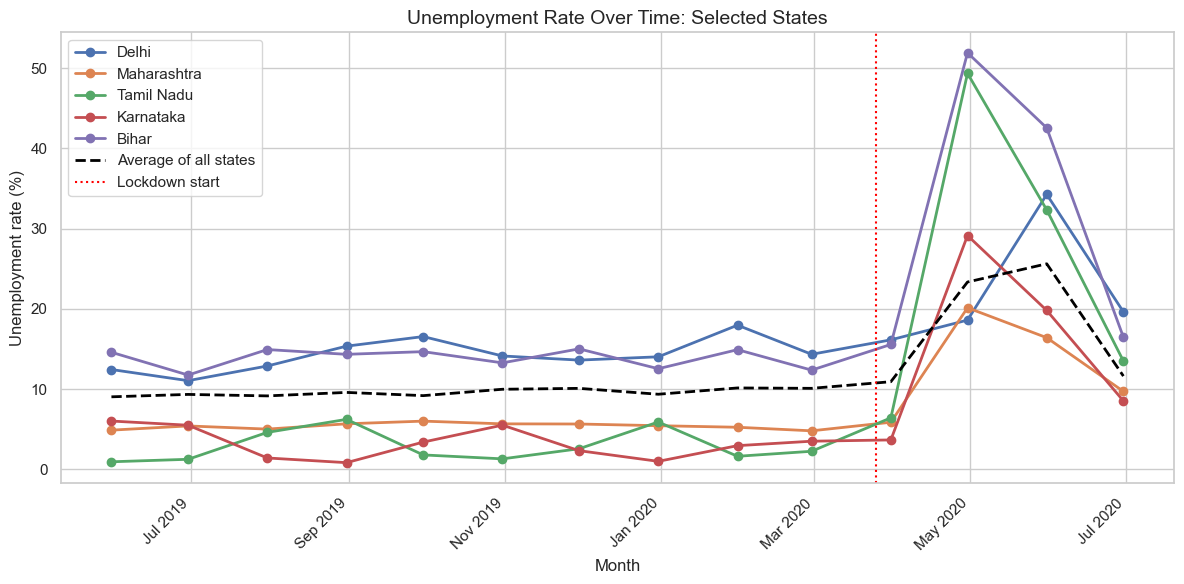

In [17]:
# Wide table: one column per state, one row per month
pivot = df.pivot_table(index='Date', columns='State', values='Unemployment_Rate', aggfunc='mean')

preferred = ['Delhi', 'Maharashtra', 'Tamil Nadu', 'Karnataka', 'Bihar']
selected = [s for s in preferred if s in pivot.columns]
if len(selected) < 3:                                          # make sure we have at least 3 states
    extra = [s for s in state_avg.index if s not in selected]
    selected += extra[:3 - len(selected)]
print('States plotted:', selected)

fig, ax = plt.subplots(figsize=(12, 6))
for state in selected:
    ax.plot(pivot.index, pivot[state], marker='o', lw=2, label=state)

# Average across all states (unweighted) for reference
ax.plot(pivot.index, pivot.mean(axis=1), color='black', ls='--', lw=2, label='Average of all states')
ax.axvline(LOCKDOWN_DATE, color='red', ls=':', lw=1.5, label='Lockdown start')

ax.set_title('Unemployment Rate Over Time: Selected States')
ax.set_xlabel('Month')
ax.set_ylabel('Unemployment rate (%)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Observation:** the states usually follow the same *shape* (flat, then a lockdown spike, then recovery), but the *height* of the spike differs a lot from state to state. Compare each line with the dashed average: states far above it were hit much harder, states below it were hit less. States with a high unemployment rate even *before* the lockdown line indicate structural unemployment rather than a COVID effect.

### 5.1 All states at once: state × month heatmap
States are sorted from highest to lowest average unemployment. Darker cells = higher unemployment.

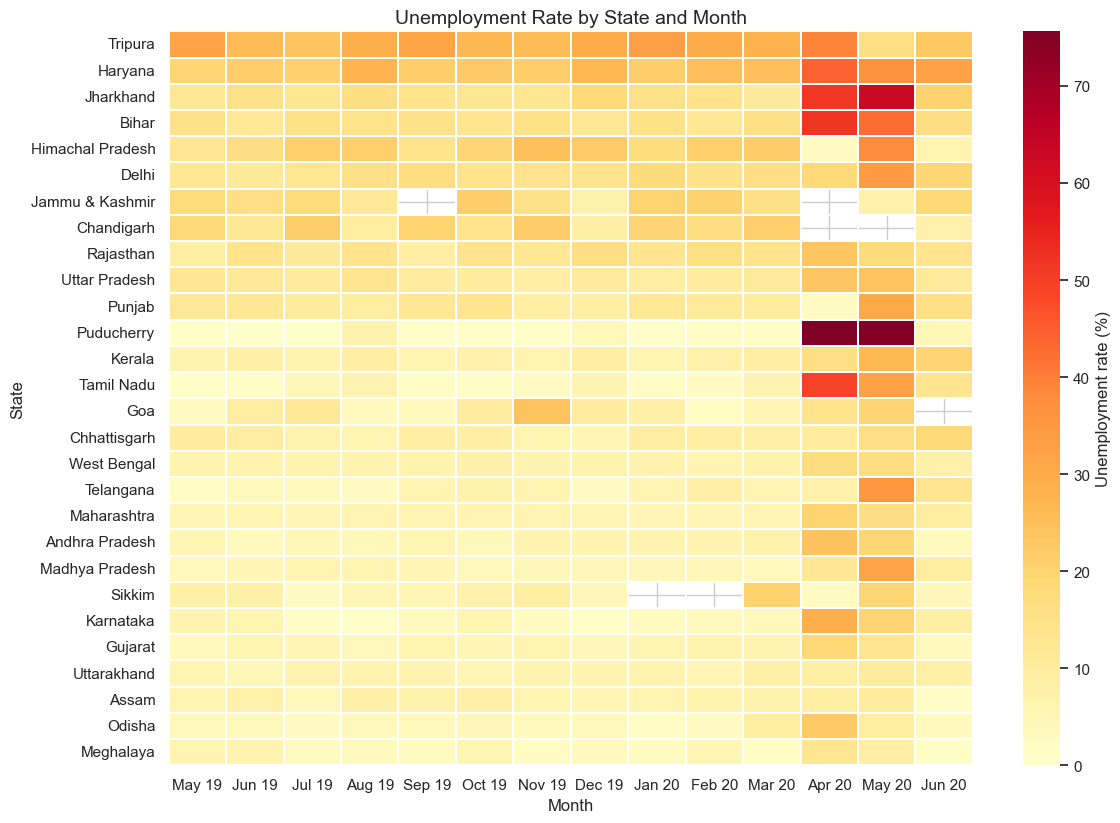

Month in which each state peaked (number of states):
Apr 2020    12
May 2020    10
Oct 2019     2
Nov 2019     2
Jun 2020     1
Mar 2020     1


In [18]:
heat = pivot.T.reindex(state_avg.index)                        # order rows by average unemployment
heat.columns = heat.columns.strftime('%b %y')

fig, ax = plt.subplots(figsize=(12, max(6, 0.3 * len(heat))))
sns.heatmap(heat, cmap='YlOrRd', linewidths=0.3, cbar_kws={'label': 'Unemployment rate (%)'}, ax=ax)
ax.set_title('Unemployment Rate by State and Month')
ax.set_xlabel('Month')
ax.set_ylabel('State')
plt.tight_layout()
plt.show()

# Which month is the peak month for most states?
peak = df.loc[df.groupby('State')['Unemployment_Rate'].idxmax(), ['State', 'Date', 'Unemployment_Rate']]
print('Month in which each state peaked (number of states):')
print(peak['Date'].dt.strftime('%b %Y').value_counts().to_string())

**Observation:** a vertical dark band (many states dark in the same month) means the shock hit almost everywhere at once, which is what a nationwide lockdown would cause. Horizontal dark rows are states that were high in most months. The peak-month count above shows how concentrated the spike was.

## 6. Top 10 States by Average Unemployment Rate

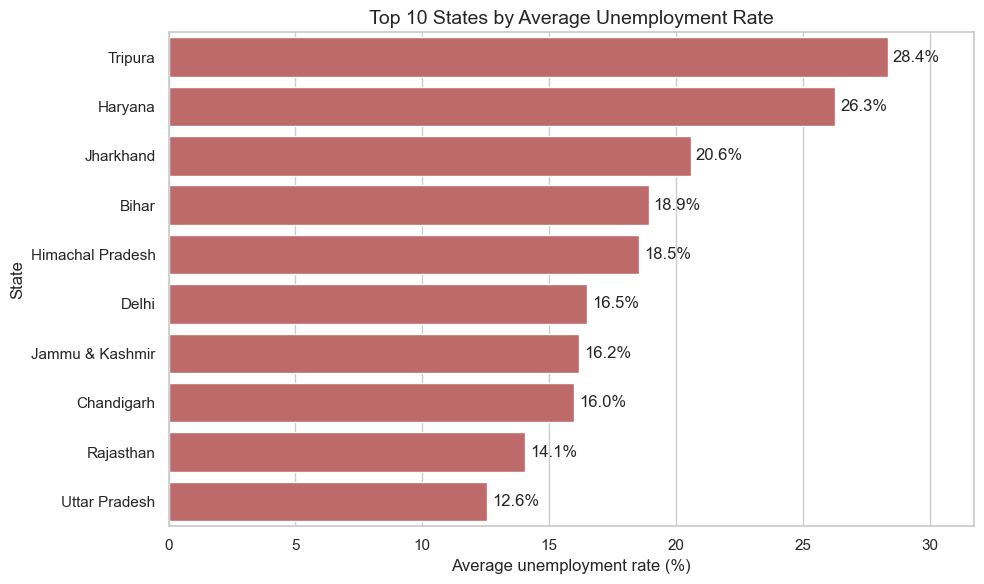

In [19]:
top10 = state_avg['Unemployment_Rate'].head(10)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index, color='indianred', ax=ax)
for i, v in enumerate(top10.values):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center')              # value labels at bar ends
ax.set_title('Top 10 States by Average Unemployment Rate')
ax.set_xlabel('Average unemployment rate (%)')
ax.set_ylabel('State')
ax.set_xlim(0, top10.max() * 1.12)
plt.tight_layout()
plt.show()

**Observation:** this ranks states by their average over the *entire* period, so it mixes normal months with lockdown months. Two things to keep in mind:
1. Small states / union territories can swing wildly on small samples, so a top position does not always mean a large number of people affected.
2. Check Section 8, which shows which of these states were already high before COVID and which jumped because of it.

## 7. Correlation Heatmap
Relationship between the unemployment rate, employment (headcount) and labour participation rate.

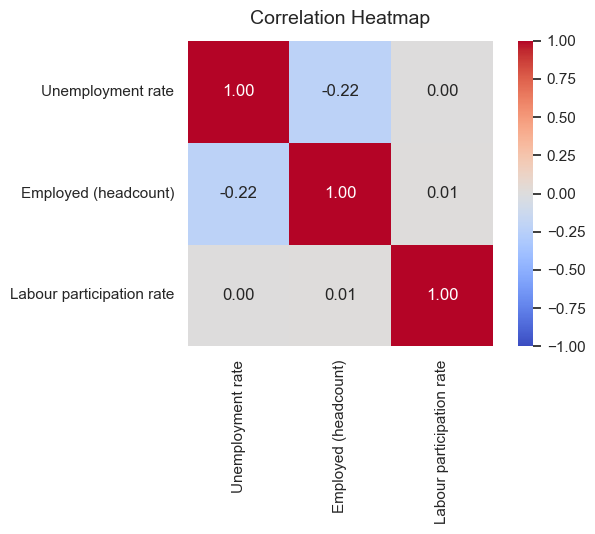

Strongest relationship: Unemployment rate  vs  Employed (headcount)  (r = -0.22)


In [20]:
corr = df[METRICS].corr()
labels = ['Unemployment rate', 'Employed (headcount)', 'Labour participation rate']
corr.index = labels
corr.columns = labels

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True)
plt.title('Correlation Heatmap', pad=12)
plt.tight_layout()
plt.show()

# Strongest relationship between two different variables
pairs = corr.where(~np.eye(len(corr), dtype=bool)).stack()
strongest = pairs.abs().idxmax()
print(f'Strongest relationship: {strongest[0]}  vs  {strongest[1]}  (r = {pairs[strongest]:.2f})')

## 8. Pre-COVID vs Post-COVID Comparison

The data is split at the start of India's lockdown (**25 March 2020**, set in Section 1). Months before it are labelled *Pre-COVID*; the lockdown month and everything after are labelled *Post-COVID*. Note that "Post-COVID" here means *after the lockdown began*, so it includes the shock **and** the recovery months.

In [21]:
df['Period'] = np.where(df['Date'] < LOCKDOWN_DATE, 'Pre-COVID', 'Post-COVID')

# How many months are in each period? (very few months = weak comparison)
months_per_period = df.groupby('Period')['Date'].nunique()
print('Months of data in each period:')
print(months_per_period.to_string())

if not {'Pre-COVID', 'Post-COVID'}.issubset(months_per_period.index):
    raise ValueError('The loaded file does not have data on both sides of the lockdown date. '
                     'Use a file that includes months before March 2020.')
if months_per_period.min() < 3:
    print('\nWARNING: one period has fewer than 3 months of data, so treat this comparison with caution.')

Months of data in each period:
Period
Post-COVID     4
Pre-COVID     10


In [22]:
# Mean of each metric in each period (average across all states and months)
overall = df.groupby('Period')[METRICS].mean().loc[['Pre-COVID', 'Post-COVID']].round(2)
change = (overall.loc['Post-COVID'] - overall.loc['Pre-COVID']).rename('Change (Post - Pre)')
overall_table = pd.concat([overall, change.to_frame().T])
display(overall_table)

pre_ur = overall.loc['Pre-COVID', 'Unemployment_Rate']
post_ur = overall.loc['Post-COVID', 'Unemployment_Rate']
print(f'\nAverage unemployment rate: {pre_ur:.2f}% before  ->  {post_ur:.2f}% after  '
      f'({post_ur - pre_ur:+.2f} percentage points)')

,Unemployment_Rate,Employed,LPR
Pre-COVID,9.51,7466027.87,43.89
Post-COVID,17.77,6517203.34,39.33
Change (Post - Pre),8.26,-948824.53,-4.56



Average unemployment rate: 9.51% before  ->  17.77% after  (+8.26 percentage points)


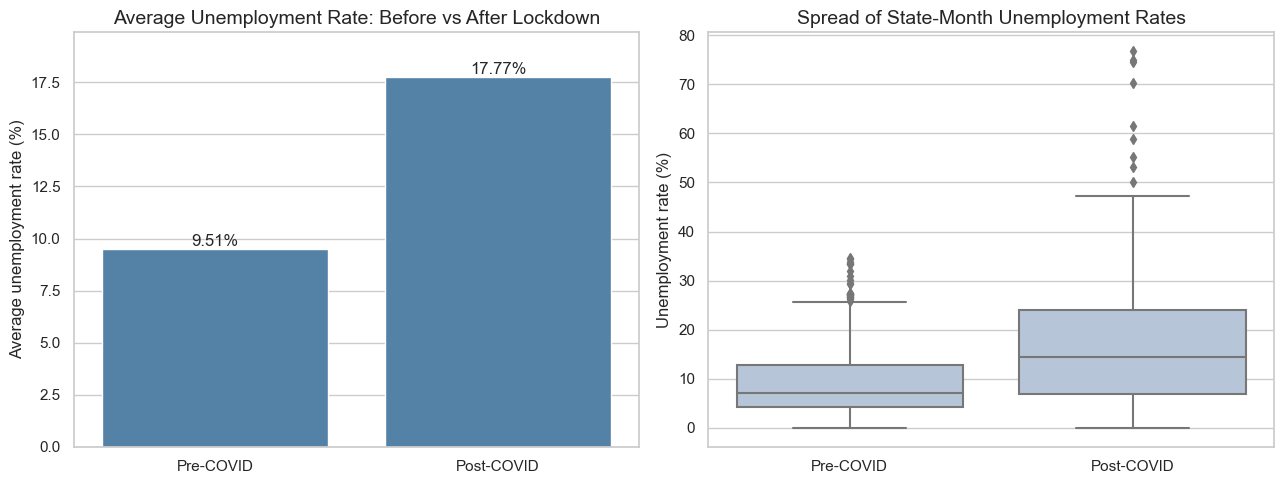

In [23]:
# Visual comparison: average (left) and spread across state-months (right)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = ['Pre-COVID', 'Post-COVID']
sns.barplot(x=overall.index, y=overall['Unemployment_Rate'], order=order, color='steelblue', ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt='%.2f%%')
axes[0].margins(y=0.12)                                         # headroom so labels are not clipped
axes[0].set_title('Average Unemployment Rate: Before vs After Lockdown')
axes[0].set_xlabel('')
axes[0].set_ylabel('Average unemployment rate (%)')

sns.boxplot(data=df, x='Period', y='Unemployment_Rate', order=order, color='lightsteelblue', ax=axes[1])
axes[1].set_title('Spread of State-Month Unemployment Rates')
axes[1].set_xlabel('')
axes[1].set_ylabel('Unemployment rate (%)')

plt.tight_layout()
plt.show()

**Observation:** the bar shows how much the *average* moved; the box plot shows how the whole *spread* changed. After the lockdown, expect the box to sit higher and to have a much longer upper tail (a few state-months with extreme unemployment), which a simple average understates.

### 8.1 State-wise change

States compared: 28 of 28


Period,Pre-COVID,Post-COVID,Change
State,,,
Puducherry,1.59,38.96,37.36
Tamil Nadu,2.84,25.40,22.57
Jharkhand,14.28,36.35,22.07
Bihar,13.83,31.63,17.80
Karnataka,3.23,15.28,12.05
Haryana,22.94,34.65,11.72
Kerala,6.99,17.95,10.96
Telangana,4.66,15.44,10.79
Madhya Pradesh,4.74,14.07,9.33


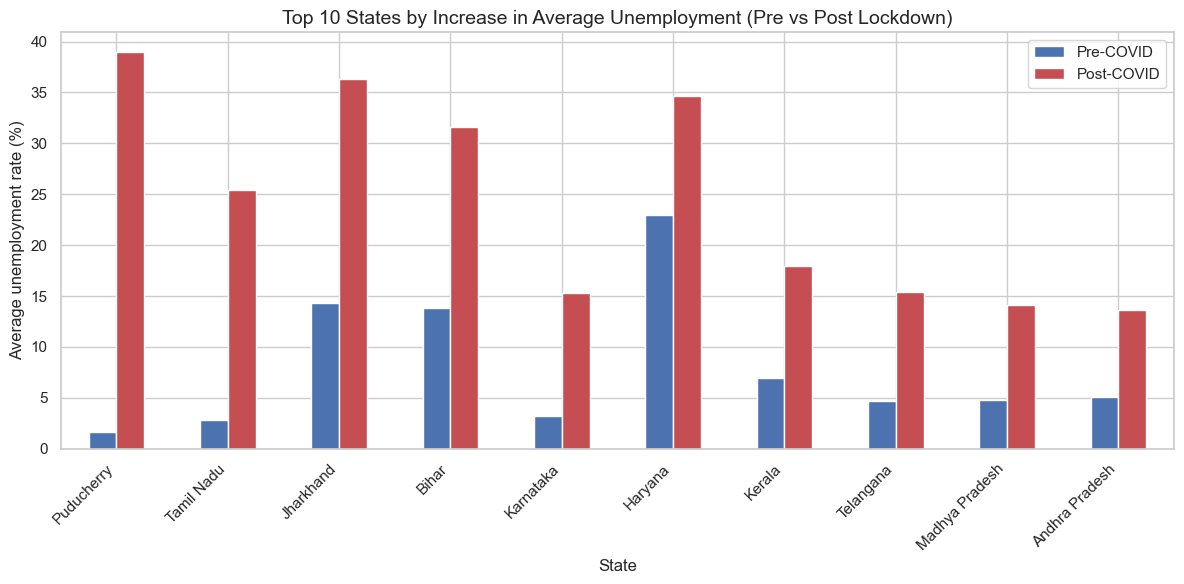

Largest increase: Puducherry (+37.4 percentage points)
Smallest change : Jammu & Kashmir (-4.3 percentage points)


In [24]:
# Average unemployment per state in each period, and the change between them
state_period = (
    df.pivot_table(index='State', columns='Period', values='Unemployment_Rate', aggfunc='mean')
      .reindex(columns=['Pre-COVID', 'Post-COVID'])
)
n_total = len(state_period)
state_period = state_period.dropna()                           # keep states present in both periods
print(f'States compared: {len(state_period)} of {n_total}')

state_period['Change'] = state_period['Post-COVID'] - state_period['Pre-COVID']
state_period = state_period.sort_values('Change', ascending=False).round(2)
display(state_period)

# Chart: the 10 states with the biggest increase
top_change = state_period.head(10)
ax = top_change[['Pre-COVID', 'Post-COVID']].plot(kind='bar', figsize=(12, 6), color=['#4c72b0', '#c44e52'])
ax.set_title('Top 10 States by Increase in Average Unemployment (Pre vs Post Lockdown)')
ax.set_xlabel('State')
ax.set_ylabel('Average unemployment rate (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='')
plt.tight_layout()
plt.show()

worst = state_period.index[0]
print(f"Largest increase: {worst} ({state_period['Change'].iloc[0]:+.1f} percentage points)")
print(f"Smallest change : {state_period.index[-1]} ({state_period['Change'].iloc[-1]:+.1f} percentage points)")

## 9. Key Findings and Limitations

In [26]:
# Auto-generated summary: every number below is computed from the loaded data
print('KEY FINDINGS (computed from the data)')
print('-' * 60)
print(f"1. Data covers {df['Date'].min():%b %Y} to {df['Date'].max():%b %Y}, "
      f"{df['State'].nunique()} states, {df['Date'].nunique()} months.")
print(f"2. Highest average unemployment: {state_avg.index[0]} ({state_avg['Unemployment_Rate'].iloc[0]:.1f}%); "
      f"lowest: {state_avg.index[-1]} ({state_avg['Unemployment_Rate'].iloc[-1]:.1f}%).")
print(f"3. Nationwide monthly average peaked at {monthly['Unemployment_Rate'].max():.1f}% in {peak_month:%b %Y}.")
print(f"4. Average unemployment moved from {pre_ur:.1f}% (pre-lockdown) to {post_ur:.1f}% (post-lockdown), "
      f"a change of {post_ur - pre_ur:+.1f} percentage points.")
print(f"5. Largest state-level increase: {state_period.index[0]} ({state_period['Change'].iloc[0]:+.1f} pp).")
print(f"6. Strongest correlation: {strongest[0]} vs {strongest[1]} (r = {pairs[strongest]:.2f}).")

KEY FINDINGS (computed from the data)
------------------------------------------------------------
1. Data covers May 2019 to Jun 2020, 28 states, 14 months.
2. Highest average unemployment: Tripura (28.4%); lowest: Meghalaya (4.8%).
3. Nationwide monthly average peaked at 24.9% in May 2020.
4. Average unemployment moved from 9.5% (pre-lockdown) to 17.8% (post-lockdown), a change of +8.3 percentage points.
5. Largest state-level increase: Puducherry (+37.4 pp).
6. Strongest correlation: Unemployment rate vs Employed (headcount) (r = -0.22).


# THANK YOU